In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("BROKE Analytics — EDA Started!")

BROKE Analytics — EDA Started!


In [3]:
df = pd.read_csv(
    "../data/processed/cleaned_student_expenses.csv",
    parse_dates=["date"]
)

df.head()

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city,day_of_week,is_weekend,expense_size
0,S001,2026-09-01,Transport,8.73,Cash,True,676,Tunis,Tuesday,False,Medium
1,S001,2026-09-01,Entertainment,8.30,Card,False,676,Tunis,Tuesday,False,Medium
2,S001,2026-09-01,Education,39.25,Card,True,676,Tunis,Tuesday,False,Large
3,S001,2026-09-02,Shopping,53.28,Cash,False,676,Tunis,Wednesday,False,Large
4,S001,2026-09-02,Shopping,93.78,Cash,False,676,Tunis,Wednesday,False,Large


In [5]:
print("Total transactions:", len(df))
print("Total students:", df["student_id"].nunique())
print("Total cities:", df["city"].nunique())
print("Total categories:", df["category"].nunique())

Total transactions: 7565
Total students: 100
Total cities: 5
Total categories: 6


In [7]:
df.describe()

,date,amount_tnd,monthly_budget
count,7565,7565.000000,7565.000000
mean,2026-09-15 10:58:59.563780352,21.606143,509.476801
min,2026-09-01 00:00:00,1.010000,252.000000
25%,2026-09-08 00:00:00,5.980000,386.000000
50%,2026-09-15 00:00:00,13.390000,516.000000
75%,2026-09-23 00:00:00,31.120000,642.000000
max,2026-09-30 00:00:00,99.890000,789.000000
std,NaN,21.727093,154.002025


In [9]:
df["category"].value_counts()

category
Coffee           1310
Entertainment    1278
Shopping         1265
Education        1256
Transport        1249
Food             1207
Name: count, dtype: int64

In [11]:
total_spending = df["amount_tnd"].sum()

print(f"Total Spending: {total_spending:,.2f} TND")

Total Spending: 163,450.47 TND


In [13]:
average_transaction = df["amount_tnd"].mean()

print(f"Average Transaction: {average_transaction:.2f} TND")

Average Transaction: 21.61 TND


In [15]:
student_spending = (
    df.groupby("student_id")["amount_tnd"]
    .sum()
)

average_student_spending = student_spending.mean()

print(
    f"Average Spending Per Student: "
    f"{average_student_spending:.2f} TND"
)

Average Spending Per Student: 1634.50 TND


In [17]:
category_spending = (
    df.groupby("category")["amount_tnd"]
    .sum()
    .sort_values(ascending=False)
)

category_spending

category
Shopping         72337.63
Education        34951.68
Entertainment    28439.43
Food             15053.69
Transport         6754.15
Coffee            5913.89
Name: amount_tnd, dtype: float64

In [19]:
category_percentage = (
    category_spending / category_spending.sum()
) * 100

category_percentage.round(2)

category
Shopping         44.26
Education        21.38
Entertainment    17.40
Food              9.21
Transport         4.13
Coffee            3.62
Name: amount_tnd, dtype: float64

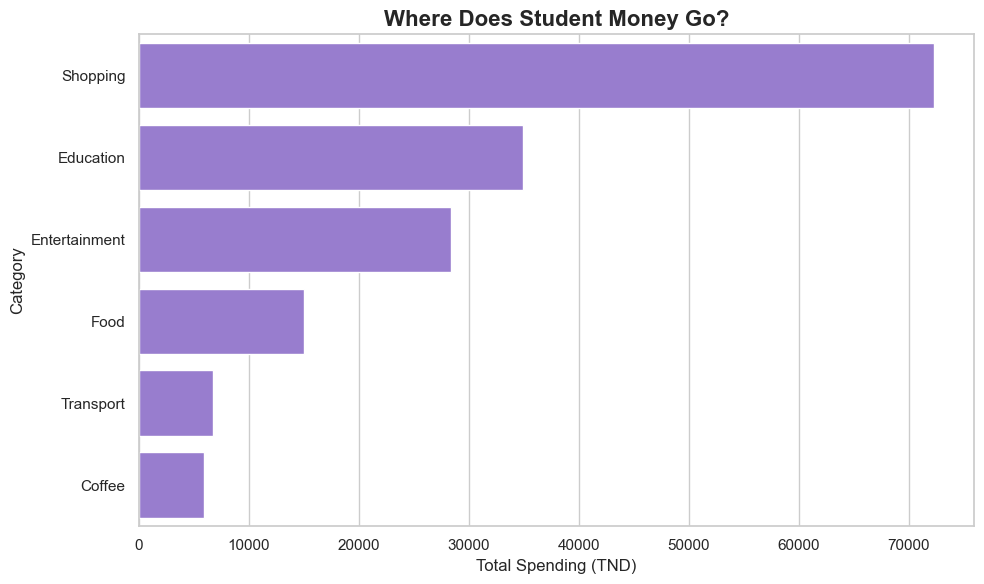

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_spending.values,
    y=category_spending.index,
    color="mediumpurple"
)

plt.title(
    "Where Does Student Money Go?",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Spending (TND)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [23]:
student_summary = (
    df.groupby("student_id")
    .agg(
        total_spending=("amount_tnd", "sum"),
        monthly_budget=("monthly_budget", "first"),
        city=("city", "first"),
        transactions=("amount_tnd", "count")
    )
    .reset_index()
)

student_summary.head()

,student_id,total_spending,monthly_budget,city,transactions
0,S001,1624.19,676,Tunis,76
1,S002,1926.78,424,Nabeul,75
2,S003,1867.68,322,Nabeul,83
3,S004,1807.61,422,Sfax,71
4,S005,1271.62,577,Sfax,60


In [25]:
student_summary["remaining_budget"] = (
    student_summary["monthly_budget"]
    - student_summary["total_spending"]
)

In [27]:
student_summary["over_budget"] = (
    student_summary["remaining_budget"] < 0
)

In [29]:
over_budget_percentage = (
    student_summary["over_budget"].mean() * 100
)

print(
    f"Students Over Budget: "
    f"{over_budget_percentage:.2f}%"
)

Students Over Budget: 100.00%


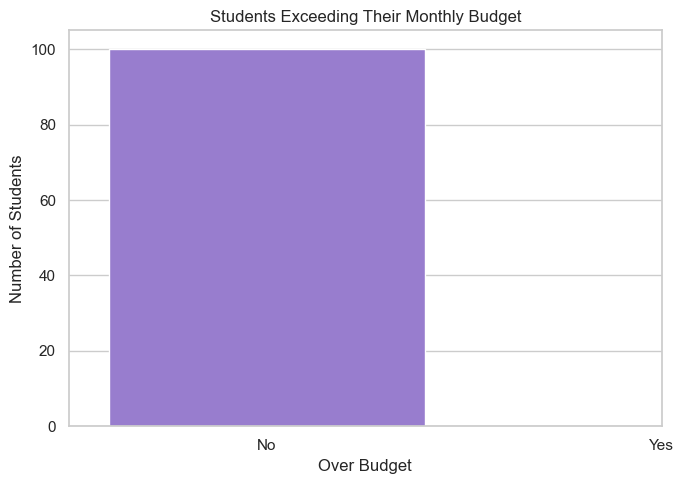

In [31]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=student_summary,
    x="over_budget",
    color="mediumpurple"
)

plt.title("Students Exceeding Their Monthly Budget")

plt.xlabel("Over Budget")
plt.ylabel("Number of Students")

plt.xticks([0, 1], ["No", "Yes"])

plt.tight_layout()
plt.show()

In [33]:
city_spending = (
    df.groupby("city")["amount_tnd"]
    .sum()
    .sort_values(ascending=False)
)

city_spending

city
Sousse      38399.45
Nabeul      36437.94
Monastir    32300.36
Tunis       30809.12
Sfax        25503.60
Name: amount_tnd, dtype: float64

In [35]:
city_average = (
    student_summary.groupby("city")["total_spending"]
    .mean()
    .sort_values(ascending=False)
)

city_average

city
Sfax        1700.240000
Nabeul      1656.270000
Tunis       1621.532632
Monastir    1615.018000
Sousse      1599.977083
Name: total_spending, dtype: float64

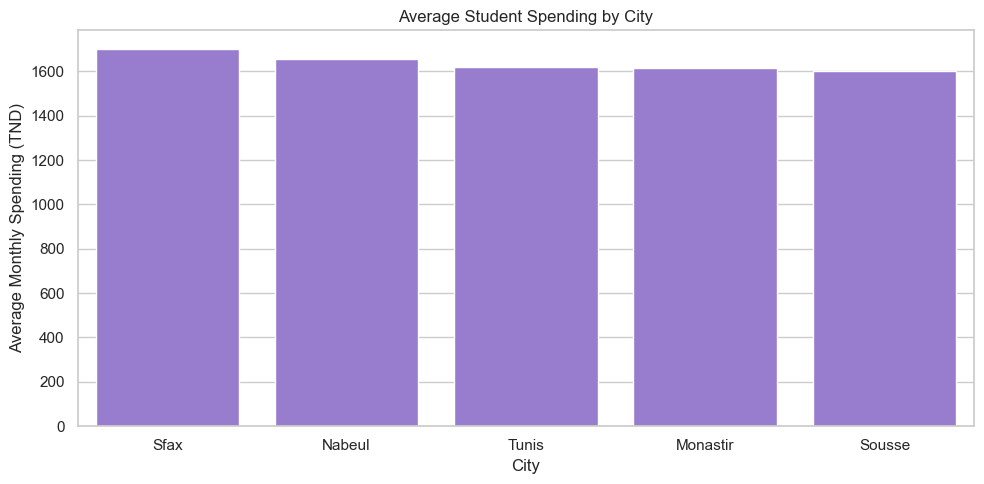

In [37]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=city_average.index,
    y=city_average.values,
    color="mediumpurple"
)

plt.title("Average Student Spending by City")

plt.xlabel("City")
plt.ylabel("Average Monthly Spending (TND)")

plt.tight_layout()
plt.show()

In [39]:
essential_spending = (
    df.groupby("is_essential")["amount_tnd"]
    .sum()
)

essential_spending

is_essential
False    106690.95
True      56759.52
Name: amount_tnd, dtype: float64

In [41]:
essential_percentage = (
    essential_spending / essential_spending.sum()
) * 100

essential_percentage

is_essential
False    65.274178
True     34.725822
Name: amount_tnd, dtype: float64

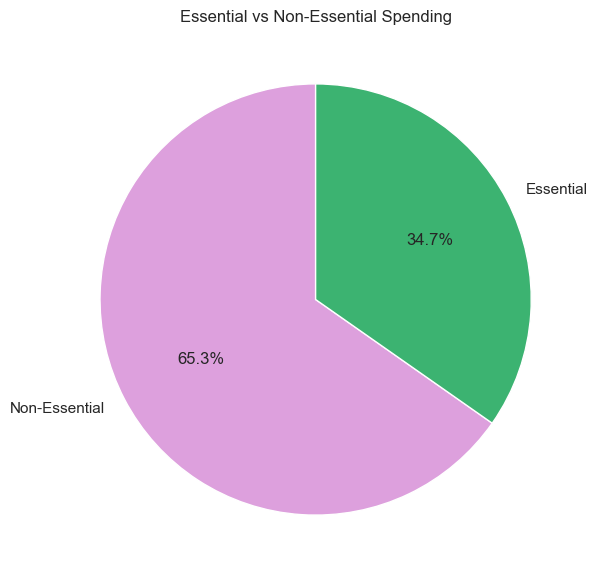

In [43]:
plt.figure(figsize=(7, 7))

plt.pie(
    essential_spending.values,
    labels=["Non-Essential", "Essential"],
    autopct="%1.1f%%",
    colors=["plum", "mediumseagreen"],
    startangle=90
)

plt.title("Essential vs Non-Essential Spending")

plt.show()

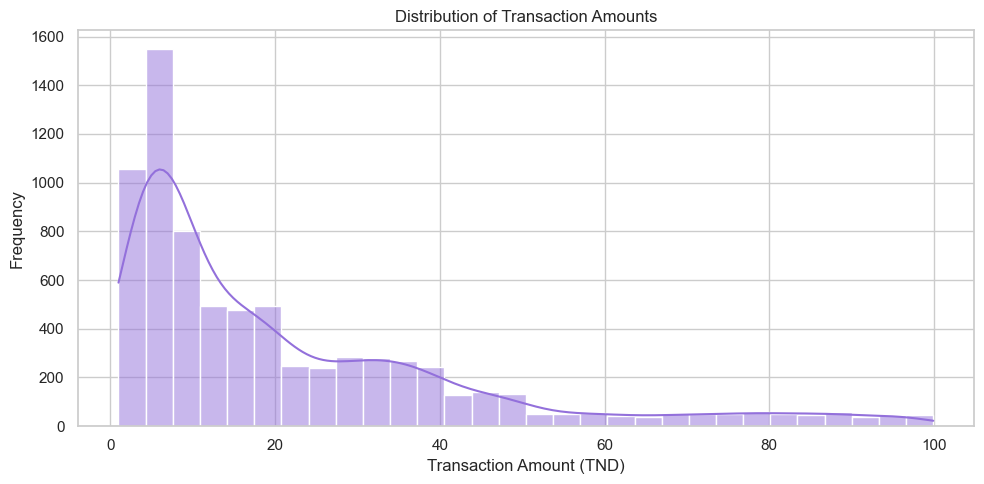

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["amount_tnd"],
    bins=30,
    kde=True,
    color="mediumpurple"
)

plt.title("Distribution of Transaction Amounts")

plt.xlabel("Transaction Amount (TND)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [47]:
print("=" * 45)
print("💸 BROKE — STUDENT FINANCIAL REPORT")
print("=" * 45)

print(f"Students: {df['student_id'].nunique()}")

print(f"Transactions: {len(df)}")

print(f"Total Spending: {total_spending:,.2f} TND")

print(
    f"Average Transaction: "
    f"{average_transaction:.2f} TND"
)

print(
    f"Average Student Spending: "
    f"{average_student_spending:.2f} TND"
)

print(
    f"Students Over Budget: "
    f"{over_budget_percentage:.2f}%"
)

print(
    f"Top Spending Category: "
    f"{category_spending.idxmax()}"
)

print("=" * 45)

💸 BROKE — STUDENT FINANCIAL REPORT
Students: 100
Transactions: 7565
Total Spending: 163,450.47 TND
Average Transaction: 21.61 TND
Average Student Spending: 1634.50 TND
Students Over Budget: 100.00%
Top Spending Category: Shopping


In [49]:
student_summary.to_csv(
    "../data/processed/student_summary.csv",
    index=False
)

print("Student summary saved successfully!")

Student summary saved successfully!
